In [1]:
import time
import os
import shutil
import sys
import h5py
import tensorflow                 as tf
import numpy                      as np
import seaborn                    as sns
import pandas                     as pd
import numpy.random               as random
from sklearn.utils            import shuffle
from sklearn.model_selection  import train_test_split
from tqdm                     import tqdm
from os                       import path
import pysftp                     as sftp
import random                     as rnd

LocalFlg           = 'False'
if (not LocalFlg):
    WORKSPACE_PATH = "/home/venturi/WORKSPACE/"
    IP             = '128.174.245.172'
    User           = "venturi"
else:
    WORKSPACE_PATH = os.getenv('WORKSPACE_PATH')  
    
import matplotlib as mpl
import matplotlib.pyplot                      as plt
plt.style.use(WORKSPACE_PATH+'/SurQCT/surqct/scripts/postprocessing/presentation.mplstyle')

print("="*50)
print(" TensorFlow version: {}".format(tf.__version__))
print(" Eager execution: {}".format(tf.executing_eagerly()))

 TensorFlow version: 2.4.1
 Eager execution: True


In [2]:
WORKSPACE_PATH      = os.environ['WORKSPACE_PATH']
SurQCTFldr      = WORKSPACE_PATH + '/SurQCT/surqct/'

RatesType           = 'KExcit'
# Dimension           = 'transfer'
Dimension           = 'nondim_N3'
# Dimension = 'N3'

ExcitType           = 'KInel'
NNRunIdx            = 14
# ExcitType           = 'KExch'
# NNRunIdx            = 2

if (Dimension == 'nondim'):
    PathToRunFld        = SurQCTFldr + '/../' + RatesType + '/all_temperatures_nondim/' + ExcitType + '/' 
elif (Dimension == 'nondim_N3'):
    PathToRunFld        = SurQCTFldr + '/../' + RatesType + '_N3_QCTLearn/all_temperatures_nondim/' + ExcitType + '/' 
elif (Dimension == 'N3'):
    PathToRunFld        = SurQCTFldr + '/../' + RatesType + '_N3_QCTLearn/all_temperatures/' + ExcitType + '/' 
else:
    PathToRunFld        = SurQCTFldr + '/../' + RatesType + '_N3_TransLearn/all_temperatures_nondim/' + ExcitType + '/' 

    
TTran               = 5000.0

MinRate             = 1.e-15
CPlotFlf            = False

iIdxVec             = np.array([1, 10, 34, 35, 82, 83, 98, 1000, 2000, 3000, 7428, 7432, 8000, 9000], dtype=int)
# iIdxVec             = np.array([2500,2600,2700,3000,2090], dtype=int)


In [3]:
#===================================================================================================================================
print("\n[SurQCT]: Loading Modules and Functions ...")

sys.path.insert(0, SurQCTFldr  + '/src/Reading/')
from Reading  import read_levelsdata, read_diatdata

InputFld = PathToRunFld + '/Run_' + str(NNRunIdx) + '/'
print(InputFld)
sys.path.insert(0, InputFld)
#===================================================================================================================================


[SurQCT]: Loading Modules and Functions ...
/home/venturi/WORKSPACE//SurQCT/surqct//../KExcit_N3_QCTLearn/all_temperatures_nondim/KInel//Run_14/


In [4]:
#===================================================================================================================================
print("\n[SurQCT]: Keep Loading Modules and Functions...")
from SurQCT_Input import inputdata

print("\n[SurQCT]: Initializing Input ...")
InputData    = inputdata(WORKSPACE_PATH, SurQCTFldr)

Prefix                    = 'Run_'
InputData.NNRunIdx        = NNRunIdx
InputData.PathToRunFld    = InputData.PathToRunFld+'/'+Prefix+str(InputData.NNRunIdx)
InputData.PathToFigFld    = InputData.PathToRunFld+'/'+InputData.PathToFigFld
InputData.PathToParamsFld = InputData.PathToRunFld+'/'+InputData.PathToParamsFld
InputData.PathToDataFld   = InputData.PathToRunFld+'/Data/'                                                               
InputData.PathToParamsFld = InputData.PathToRunFld+'/Params/' 
    
# ## N2 from N3
if (Dimension == 'nondim'):
    InputData.DefineModelIntFlg  = 0
    InputData.TrainIntFlg        = 0
    InputData.PathToLevelsFile = [WORKSPACE_PATH + '/Air_Database/Run_0D/database/levels/N2_LeRoy_log_nd.csv',
                                  WORKSPACE_PATH + '/Air_Database/Run_0D/database/levels/N2_LeRoy_log_nd.csv']
    InputData.Molecules       = ['N2','N2'] 
    InputData.PathToDiatFile  = [WORKSPACE_PATH + '/CoarseAIR/coarseair/dtb/Molecules/N2/LeRoy/MyLeroy_FromRobyn.inp',
                                 WORKSPACE_PATH + '/CoarseAIR/coarseair/dtb/Molecules/N2/LeRoy/MyLeroy_FromRobyn.inp']   
    InputData.PathToHDF5File  = InputData.WORKSPACE_PATH  + '/Air_Database/HDF5_Database_semiClassicalApprox/N3_NASA.hdf5'
elif (Dimension == 'nondim_N3'):
    InputData.DefineModelIntFlg  = 0
    InputData.TrainIntFlg        = 0
elif (Dimension == 'N3'):
    InputData.DefineModelIntFlg  = 0
    InputData.TrainIntFlg        = 0
elif(Dimension == 'transfer'):
    InputData.DefineModelIntFlg  = 1
    InputData.TrainIntFlg        = 0
# InputData.PathToLevelsFile= [InputData.WORKSPACE_PATH + '/Air_Database/Run_0D/database/levels/N2_LeRoy_Bottom_Vib_we_nd.csv',
#                              InputData.WORKSPACE_PATH + '/Air_Database/Run_0D/database/levels/N2_LeRoy_Bottom_Vib_we_nd.csv']



[SurQCT]: Keep Loading Modules and Functions...

[SurQCT]: Initializing Input ...


In [5]:
#===================================================================================================================================
print("\n[SurQCT]: Loading Final Modules ... ")

sys.path.insert(0, SurQCTFldr  + '/src/Model/' + InputData.ApproxModel + '/')
from Model import model

NN_KExcit                    = model(InputData, InputData.PathToRunFld, None, None)
NN_KExcit.load_params(InputData.PathToParamsFld)
#===================================================================================================================================


[SurQCT]: Loading Final Modules ... 
[SurQCT]:   Variables Selected for Training:
[SurQCT]:     x =  ['log_EVib_i', 'log_ERot_i', 'log_EVibR_i', 'log_ERotR_i', 'ri_i', 'log_rorMin_i', 'TTran_i', 'log_EVib_Delta', 'log_ERot_Delta', 'log_EVibR_Delta', 'log_ERotR_Delta', 'ri_Delta', 'log_rorMin_Delta', 'TTran_Delta']
[SurQCT]:     y =  KExcit
[SurQCT]:   Loading ML Model from Folder: /home/venturi/WORKSPACE//SurQCT/surqct//../KExcit_N3_QCTLearn/all_temperatures_nondim/KInel//Run_14/MyModel
[SurQCT]:   Restoring ML Model Weigths to File: /home/venturi/WORKSPACE//SurQCT/surqct//../KExcit_N3_QCTLearn/all_temperatures_nondim/KInel//Run_14/MyModel/MyWeights.h5
[SurQCT]:   Loading ML Model Parameters from File:  /home/venturi/WORKSPACE//SurQCT/surqct//../KExcit_N3_QCTLearn/all_temperatures_nondim/KInel//Run_14/Params//ModelCheckpoint/cp-0029.ckpt


In [6]:
#===================================================================================================================================
OtherVar           = InputData.OtherVar
xVarsVec_i         = InputData.xVarsVec_i + ['vqn','jqn']
#xVarsVec_i         = InputData.xVarsVec_i + ['vqn']
xVarsVec_Delta     = InputData.xVarsVec_Delta
xVarsVec           = list(set(xVarsVec_i) | set(xVarsVec_Delta))
print('[SurQCT]:   Reading Variables: ', xVarsVec)

InputData.MultFact = 1.e+9
MinValueTrain      = 1.e-16 * InputData.MultFact
MinValueTest       = 1.e-16 * InputData.MultFact
NoiseSD            = 1.e-13 * InputData.MultFact

NMolecules         = len(InputData.PathToLevelsFile)

InputData.iLevelsVecTest = list(np.array(InputData.iLevelsVecTest) - 1)

[SurQCT]:   Reading Variables:  ['ri', 'jqn', 'log_rorMin', 'log_ERotR', 'log_EVibR', 'vqn', 'log_EVib', 'log_ERot']


In [7]:
#===================================================================================================================================
### Reading Levels Info of Initial and Final Molecules
LevelsData = []
DiatData   = []
NLevels    = []
for iMol in range(NMolecules):

    LevelsDataTemp = read_levelsdata(InputData.PathToLevelsFile[iMol], xVarsVec, '')
    LevelsData.append(LevelsDataTemp)

    DiatDataTemp = read_diatdata(InputData.PathToDiatFile[iMol], InputData.Molecules[iMol], np.array([TTran]), np.array([TTran]))
    DiatData.append(DiatDataTemp)

    NLevelsTemp    = LevelsDataTemp.shape[0]
    NLevels.append(NLevelsTemp)

[SurQCT]:   Reading Molecular Levels Data from: /home/venturi/WORKSPACE//Air_Database/Run_0D/database/levels/N2_LeRoy_log_nd.csv
[SurQCT]:   Reading Molecular Levels Data from: /home/venturi/WORKSPACE//CoarseAIR/coarseair/dtb/Molecules/N2/LeRoy/MyLeroy_FromRobyn.inp
[SurQCT]:   Reading Molecular Levels Data from: /home/venturi/WORKSPACE//Air_Database/Run_0D/database/levels/N2_LeRoy_log_nd.csv
[SurQCT]:   Reading Molecular Levels Data from: /home/venturi/WORKSPACE//CoarseAIR/coarseair/dtb/Molecules/N2/LeRoy/MyLeroy_FromRobyn.inp


In [8]:
#=======================================================================================================================================
# Reading Excitation Rates Data 
def read_kexcitdata(InputData, PathToHDF5File, TTra, TInt, NProcTypes):
    print('[SurQCT]:       Reading HDF5 File from: ' + PathToHDF5File + ' for Excitation Rates at Temperature ' + str(int(TTra)) + 'K')

    HDF5Exist_Flg = path.exists(PathToHDF5File)
    if (HDF5Exist_Flg):
        f = h5py.File(PathToHDF5File, 'a')
    else:
        f = {'key': 'value'}

    TStr = 'T_' + str(int(TTra)) + '_' + str(int(TInt)) + '/Rates/'
    grp  = f[TStr]

    Data  = grp["Inel"]
    KInel = Data[...]

    KOther = []
    for iProc in range(2, NProcTypes):
        ExchStr    = "Exch_" + str(iProc-1)
        Data       = grp[ExchStr] 
        KOtherTemp = Data[...]
        KOther.append(KOtherTemp)

    f.close()   


    return KInel, KOther
#=======================================================================================================================================

In [9]:
KInelMat, KExchMatList = read_kexcitdata(InputData, InputData.PathToHDF5File, TTran, TTran, 3)

if (ExcitType == 'KInel'):
    KExcit = KInelMat
elif (ExcitType == 'KExch'):
    KExcit = KExchMatList[0]
else:
    KExcit = KInelMat + KExchMatList[0]

[SurQCT]:       Reading HDF5 File from: /home/venturi/WORKSPACE//Air_Database/HDF5_Database_semiClassicalApprox/N3_NASA.hdf5 for Excitation Rates at Temperature 5000K


[SurQCT]:     Generating Inelastic and Exchange Rate Matrices:   0%|          | 0/61 [00:00<?, ?it/s]

Level: 0; vqn: 0; jqn:0


[SurQCT]:     Generating Inelastic and Exchange Rate Matrices:   2%|▏         | 1/61 [00:00<00:44,  1.34it/s]

Level: 34; vqn: 1; jqn:0


[SurQCT]:     Generating Inelastic and Exchange Rate Matrices:   3%|▎         | 2/61 [00:01<00:35,  1.64it/s]

Level: 82; vqn: 2; jqn:0


[SurQCT]:     Generating Inelastic and Exchange Rate Matrices:   5%|▍         | 3/61 [00:01<00:32,  1.76it/s]

Level: 141; vqn: 3; jqn:0


[SurQCT]:     Generating Inelastic and Exchange Rate Matrices:   7%|▋         | 4/61 [00:02<00:31,  1.83it/s]

Level: 209; vqn: 4; jqn:0


[SurQCT]:     Generating Inelastic and Exchange Rate Matrices:   8%|▊         | 5/61 [00:02<00:29,  1.87it/s]

Level: 285; vqn: 5; jqn:0


[SurQCT]:     Generating Inelastic and Exchange Rate Matrices:  10%|▉         | 6/61 [00:03<00:29,  1.89it/s]

Level: 368; vqn: 6; jqn:0


[SurQCT]:     Generating Inelastic and Exchange Rate Matrices:  11%|█▏        | 7/61 [00:03<00:28,  1.90it/s]

Level: 458; vqn: 7; jqn:0


[SurQCT]:     Generating Inelastic and Exchange Rate Matrices:  13%|█▎        | 8/61 [00:04<00:27,  1.90it/s]

Level: 554; vqn: 8; jqn:0


[SurQCT]:     Generating Inelastic and Exchange Rate Matrices:  15%|█▍        | 9/61 [00:04<00:27,  1.91it/s]

Level: 656; vqn: 9; jqn:0


[SurQCT]:     Generating Inelastic and Exchange Rate Matrices:  16%|█▋        | 10/61 [00:05<00:26,  1.93it/s]

Level: 759; vqn: 10; jqn:0


[SurQCT]:     Generating Inelastic and Exchange Rate Matrices:  18%|█▊        | 11/61 [00:05<00:25,  1.93it/s]

Level: 869; vqn: 11; jqn:0


[SurQCT]:     Generating Inelastic and Exchange Rate Matrices:  20%|█▉        | 12/61 [00:06<00:25,  1.93it/s]

Level: 985; vqn: 12; jqn:0


[SurQCT]:     Generating Inelastic and Exchange Rate Matrices:  21%|██▏       | 13/61 [00:06<00:25,  1.92it/s]

Level: 1104; vqn: 13; jqn:0


[SurQCT]:     Generating Inelastic and Exchange Rate Matrices:  23%|██▎       | 14/61 [00:07<00:25,  1.85it/s]

Level: 1227; vqn: 14; jqn:0


[SurQCT]:     Generating Inelastic and Exchange Rate Matrices:  25%|██▍       | 15/61 [00:08<00:24,  1.91it/s]

Level: 1354; vqn: 15; jqn:0


[SurQCT]:     Generating Inelastic and Exchange Rate Matrices:  26%|██▌       | 16/61 [00:08<00:22,  1.96it/s]

Level: 1487; vqn: 16; jqn:0


[SurQCT]:     Generating Inelastic and Exchange Rate Matrices:  28%|██▊       | 17/61 [00:08<00:22,  2.00it/s]

Level: 1619; vqn: 17; jqn:0


[SurQCT]:     Generating Inelastic and Exchange Rate Matrices:  30%|██▉       | 18/61 [00:09<00:21,  2.03it/s]

Level: 1755; vqn: 18; jqn:0


[SurQCT]:     Generating Inelastic and Exchange Rate Matrices:  31%|███       | 19/61 [00:09<00:20,  2.03it/s]

Level: 1898; vqn: 19; jqn:0


[SurQCT]:     Generating Inelastic and Exchange Rate Matrices:  33%|███▎      | 20/61 [00:10<00:20,  2.04it/s]

Level: 2043; vqn: 20; jqn:0


<ipython-input-10-ece15cf69663>:148: RuntimeWarning: More than 20 figures have been opened. Figures created through the pyplot interface (`matplotlib.pyplot.figure`) are retained until explicitly closed and may consume too much memory. (To control this warning, see the rcParam `figure.max_open_warning`).
  fig = plt.figure(figsize=(12,8))
[SurQCT]:     Generating Inelastic and Exchange Rate Matrices:  34%|███▍      | 21/61 [00:10<00:19,  2.06it/s]

Level: 2186; vqn: 21; jqn:0


[SurQCT]:     Generating Inelastic and Exchange Rate Matrices:  36%|███▌      | 22/61 [00:11<00:18,  2.07it/s]

Level: 2337; vqn: 22; jqn:0


[SurQCT]:     Generating Inelastic and Exchange Rate Matrices:  38%|███▊      | 23/61 [00:11<00:18,  2.07it/s]

Level: 2490; vqn: 23; jqn:0


[SurQCT]:     Generating Inelastic and Exchange Rate Matrices:  39%|███▉      | 24/61 [00:12<00:17,  2.07it/s]

Level: 2641; vqn: 24; jqn:0


[SurQCT]:     Generating Inelastic and Exchange Rate Matrices:  41%|████      | 25/61 [00:12<00:17,  2.08it/s]

Level: 2800; vqn: 25; jqn:0


[SurQCT]:     Generating Inelastic and Exchange Rate Matrices:  43%|████▎     | 26/61 [00:13<00:16,  2.08it/s]

Level: 2955; vqn: 26; jqn:0


[SurQCT]:     Generating Inelastic and Exchange Rate Matrices:  44%|████▍     | 27/61 [00:13<00:16,  2.09it/s]

Level: 3118; vqn: 27; jqn:0


[SurQCT]:     Generating Inelastic and Exchange Rate Matrices:  46%|████▌     | 28/61 [00:14<00:15,  2.10it/s]

Level: 3279; vqn: 28; jqn:0


[SurQCT]:     Generating Inelastic and Exchange Rate Matrices:  48%|████▊     | 29/61 [00:14<00:15,  2.11it/s]

Level: 3445; vqn: 29; jqn:0


[SurQCT]:     Generating Inelastic and Exchange Rate Matrices:  49%|████▉     | 30/61 [00:15<00:14,  2.12it/s]

Level: 3608; vqn: 30; jqn:0


[SurQCT]:     Generating Inelastic and Exchange Rate Matrices:  51%|█████     | 31/61 [00:15<00:14,  2.13it/s]

Level: 3776; vqn: 31; jqn:0


[SurQCT]:     Generating Inelastic and Exchange Rate Matrices:  52%|█████▏    | 32/61 [00:16<00:13,  2.13it/s]

Level: 3942; vqn: 32; jqn:0


[SurQCT]:     Generating Inelastic and Exchange Rate Matrices:  54%|█████▍    | 33/61 [00:16<00:13,  2.14it/s]

Level: 4111; vqn: 33; jqn:0


[SurQCT]:     Generating Inelastic and Exchange Rate Matrices:  56%|█████▌    | 34/61 [00:17<00:12,  2.15it/s]

Level: 4276; vqn: 34; jqn:0


[SurQCT]:     Generating Inelastic and Exchange Rate Matrices:  57%|█████▋    | 35/61 [00:17<00:12,  2.15it/s]

Level: 4446; vqn: 35; jqn:0


[SurQCT]:     Generating Inelastic and Exchange Rate Matrices:  59%|█████▉    | 36/61 [00:17<00:11,  2.16it/s]

Level: 4614; vqn: 36; jqn:0


[SurQCT]:     Generating Inelastic and Exchange Rate Matrices:  61%|██████    | 37/61 [00:18<00:11,  2.16it/s]

Level: 4784; vqn: 37; jqn:0


[SurQCT]:     Generating Inelastic and Exchange Rate Matrices:  62%|██████▏   | 38/61 [00:18<00:10,  2.17it/s]

Level: 4956; vqn: 38; jqn:0


[SurQCT]:     Generating Inelastic and Exchange Rate Matrices:  64%|██████▍   | 39/61 [00:19<00:10,  2.18it/s]

Level: 5121; vqn: 39; jqn:0


[SurQCT]:     Generating Inelastic and Exchange Rate Matrices:  66%|██████▌   | 40/61 [00:19<00:09,  2.19it/s]

Level: 5290; vqn: 40; jqn:0


[SurQCT]:     Generating Inelastic and Exchange Rate Matrices:  67%|██████▋   | 41/61 [00:20<00:09,  2.19it/s]

Level: 5453; vqn: 41; jqn:0


[SurQCT]:     Generating Inelastic and Exchange Rate Matrices:  69%|██████▉   | 42/61 [00:20<00:08,  2.20it/s]

Level: 5614; vqn: 42; jqn:0


[SurQCT]:     Generating Inelastic and Exchange Rate Matrices:  70%|███████   | 43/61 [00:21<00:08,  2.21it/s]

Level: 5774; vqn: 43; jqn:0


[SurQCT]:     Generating Inelastic and Exchange Rate Matrices:  72%|███████▏  | 44/61 [00:21<00:07,  2.18it/s]

Level: 5927; vqn: 44; jqn:0


[SurQCT]:     Generating Inelastic and Exchange Rate Matrices:  74%|███████▍  | 45/61 [00:22<00:07,  2.15it/s]

Level: 6084; vqn: 45; jqn:0


[SurQCT]:     Generating Inelastic and Exchange Rate Matrices:  75%|███████▌  | 46/61 [00:22<00:07,  2.14it/s]

Level: 6231; vqn: 46; jqn:0


[SurQCT]:     Generating Inelastic and Exchange Rate Matrices:  77%|███████▋  | 47/61 [00:23<00:07,  1.97it/s]

Level: 6373; vqn: 47; jqn:0


[SurQCT]:     Generating Inelastic and Exchange Rate Matrices:  79%|███████▊  | 48/61 [00:23<00:06,  2.00it/s]

Level: 6512; vqn: 48; jqn:0


[SurQCT]:     Generating Inelastic and Exchange Rate Matrices:  80%|████████  | 49/61 [00:24<00:05,  2.03it/s]

Level: 6643; vqn: 49; jqn:0


[SurQCT]:     Generating Inelastic and Exchange Rate Matrices:  82%|████████▏ | 50/61 [00:24<00:05,  2.06it/s]

Level: 6769; vqn: 50; jqn:0


[SurQCT]:     Generating Inelastic and Exchange Rate Matrices:  84%|████████▎ | 51/61 [00:25<00:04,  2.08it/s]

Level: 6883; vqn: 51; jqn:0


[SurQCT]:     Generating Inelastic and Exchange Rate Matrices:  85%|████████▌ | 52/61 [00:25<00:04,  2.09it/s]

Level: 6992; vqn: 52; jqn:0


[SurQCT]:     Generating Inelastic and Exchange Rate Matrices:  87%|████████▋ | 53/61 [00:26<00:03,  2.10it/s]

Level: 7091; vqn: 53; jqn:0


[SurQCT]:     Generating Inelastic and Exchange Rate Matrices:  89%|████████▊ | 54/61 [00:26<00:03,  2.10it/s]

Level: 7171; vqn: 54; jqn:0


[SurQCT]:     Generating Inelastic and Exchange Rate Matrices:  90%|█████████ | 55/61 [00:26<00:02,  2.11it/s]

Level: 7249; vqn: 55; jqn:0


[SurQCT]:     Generating Inelastic and Exchange Rate Matrices:  92%|█████████▏| 56/61 [00:27<00:02,  2.13it/s]

Level: 7307; vqn: 56; jqn:0


[SurQCT]:     Generating Inelastic and Exchange Rate Matrices:  93%|█████████▎| 57/61 [00:27<00:01,  2.12it/s]

Level: 7352; vqn: 57; jqn:0


[SurQCT]:     Generating Inelastic and Exchange Rate Matrices:  95%|█████████▌| 58/61 [00:28<00:01,  2.13it/s]

Level: 7391; vqn: 58; jqn:0


[SurQCT]:     Generating Inelastic and Exchange Rate Matrices:  97%|█████████▋| 59/61 [00:28<00:00,  2.00it/s]

Level: 7415; vqn: 59; jqn:0


[SurQCT]:     Generating Inelastic and Exchange Rate Matrices:  98%|█████████▊| 60/61 [00:29<00:00,  2.04it/s]

Level: 7427; vqn: 60; jqn:0


[SurQCT]:     Generating Inelastic and Exchange Rate Matrices: 100%|██████████| 61/61 [00:29<00:00,  2.04it/s]


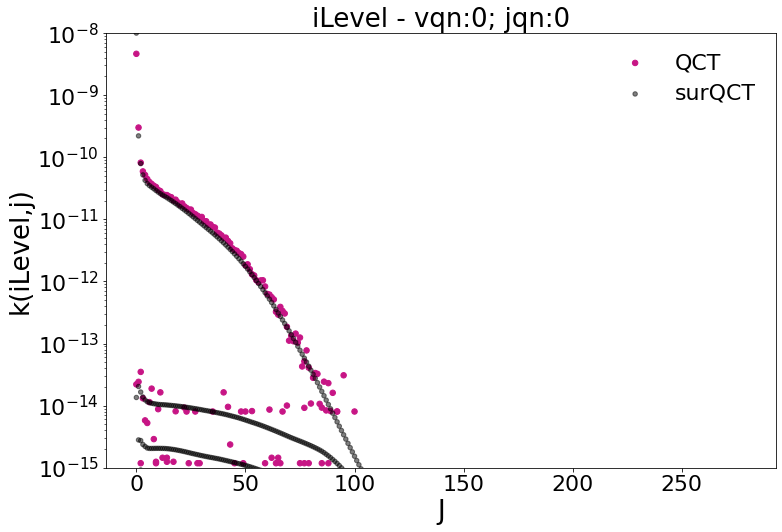

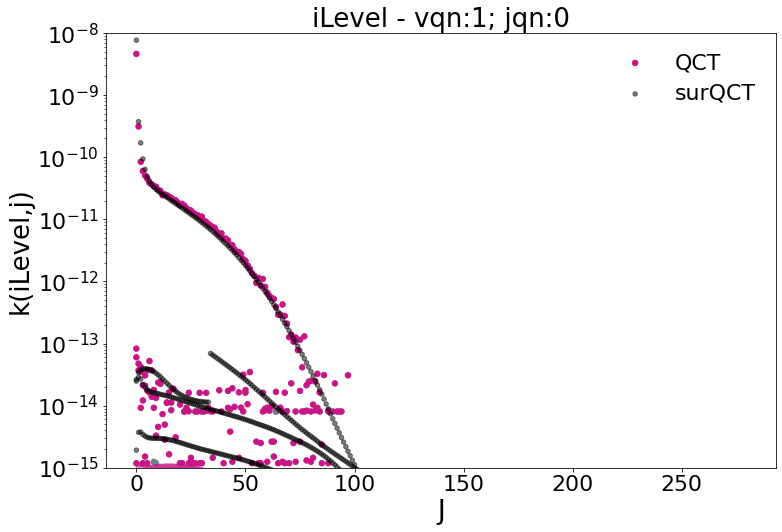

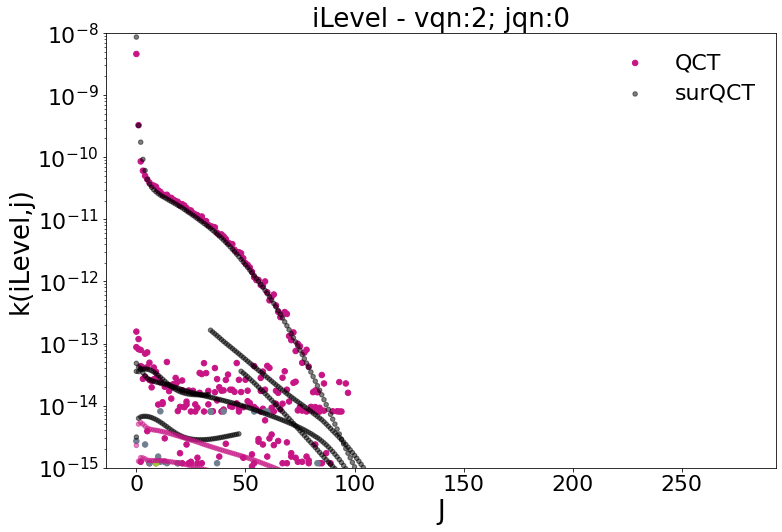

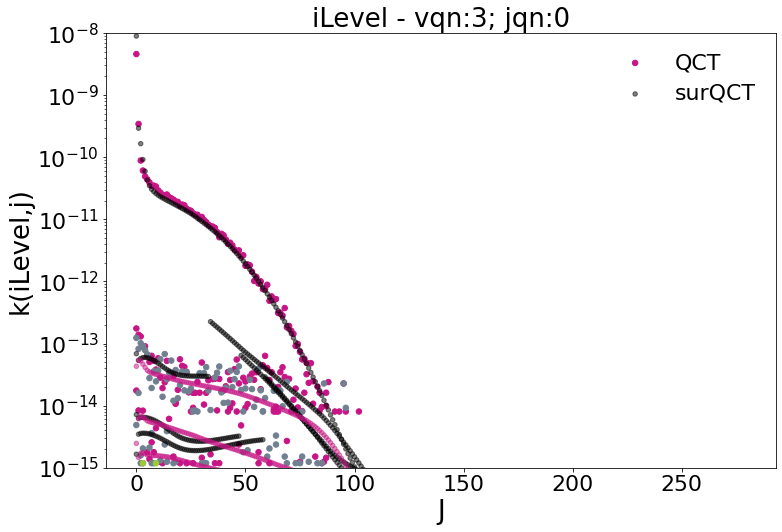

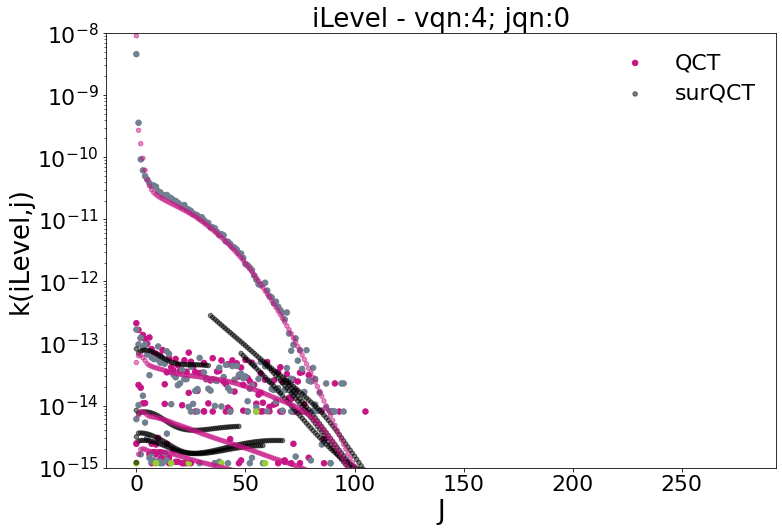

...

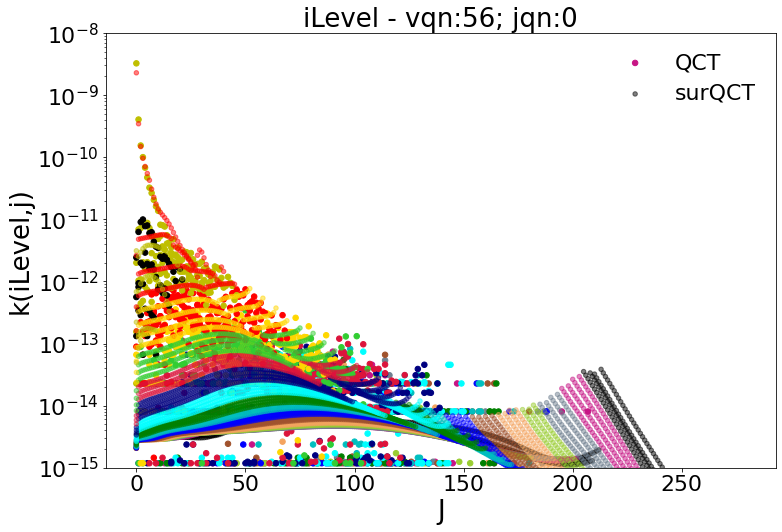

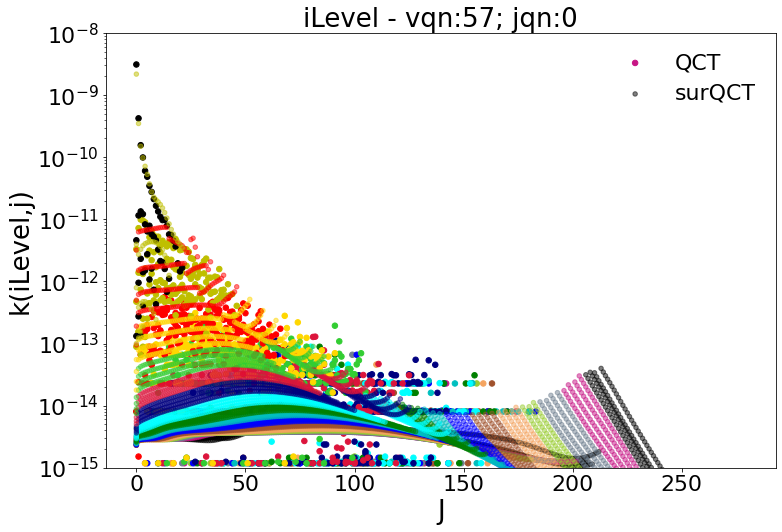

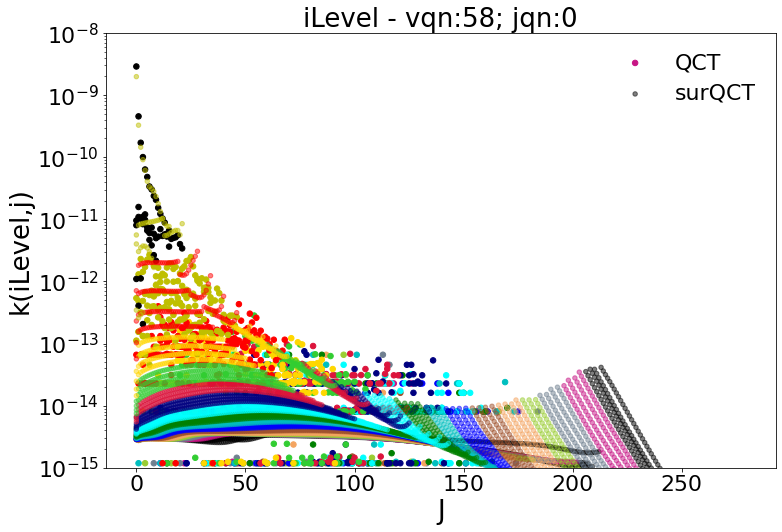

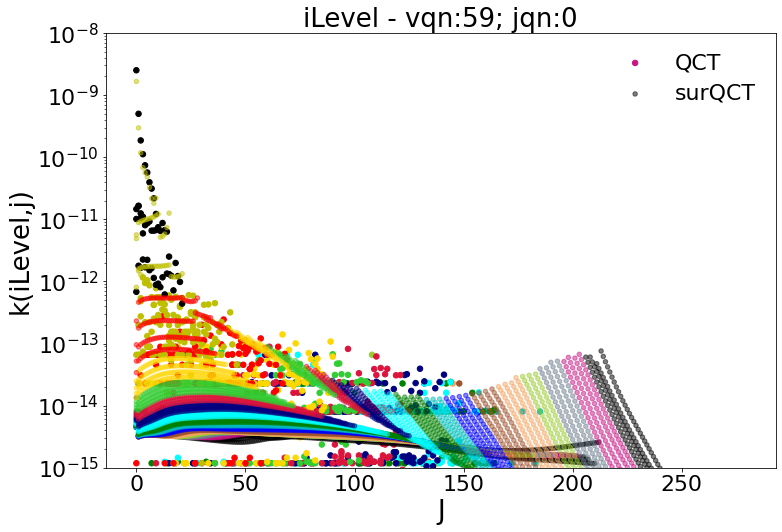

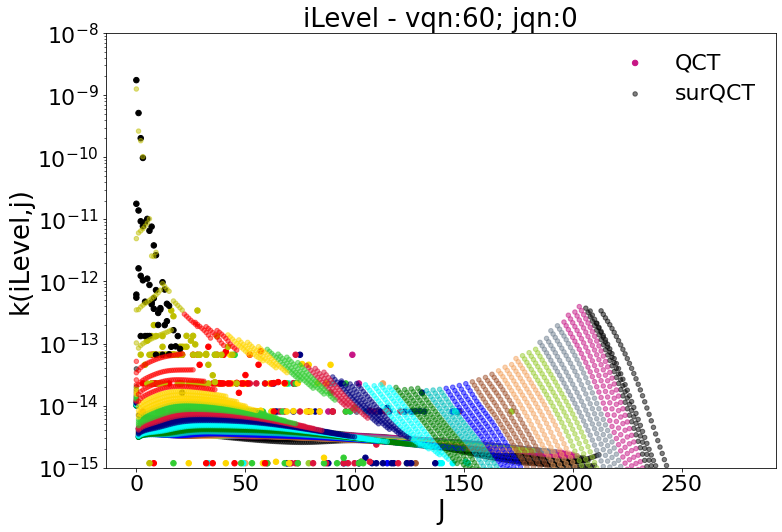

In [10]:
# iIdxVec             = np.array([83], dtype=int)
# iIdxVec             = np.array([7428,7429,7430,7432], dtype=int)
# iIdxVec             = np.array([1, 10, 34, 35, 81, 82], dtype=int)
# iIdxVec             = np.array([7000, 7200, 7250, 7251, 7300], dtype=int)
# iIdxVec             = np.array([1, 10, 34, 35, 82, 83, 98, 1000, 2000, 3000, 7428, 7432, 7250, 7251, 8000, 9000], dtype=int)

JqnVec_toWrite=np.linspace(0, 1, num=1, endpoint=False,dtype=int)
JqnVec = DiatData[0]['jqn'].to_numpy(int)

iIdxVec=np.empty(0,dtype=int)

for i in range(np.size(JqnVec_toWrite)):    
    iDxVecTemp = [idx+1 for idx in np.arange(NLevels[0]) if (JqnVec[idx] == JqnVec_toWrite[i])]
    iIdxVec=np.append(iIdxVec,iDxVecTemp)

iterI=[iIdxVec[8]]
### Loop on Initial States
Str = 'q_'+str(int(TTran))
for iIdx in tqdm(iIdxVec, desc='[SurQCT]:     Generating Inelastic and Exchange Rate Matrices'):

    iIdx -= 1  # Index in python starts from 0
    
    print('Level: '+str(iIdx)+'; vqn: '+str(DiatData[0]['vqn'].to_numpy()[iIdx])+'; jqn:'+str(DiatData[0]['jqn'].to_numpy()[iIdx]))
    time.sleep(0.02)
    
    if (InputData.ExoEndoFlg):
        jIdxVec           = [jIdx for jIdx in np.arange(NLevels[1]) if (DiatData[1]['EInt'].to_numpy()[jIdx] <= DiatData[0]['EInt'].to_numpy()[iIdx])]
        jIdxVecNo         = [jIdx for jIdx in np.arange(NLevels[1]) if (DiatData[1]['EInt'].to_numpy()[jIdx] > DiatData[0]['EInt'].to_numpy()[iIdx])]
        RatioNo           = [DiatData[0][Str].to_numpy()[iIdx]/DiatData[1][Str].to_numpy()[jIdx] for jIdx in np.arange(NLevels[1]) if (DiatData[1]['EInt'].to_numpy()[jIdx] > DiatData[0]['EInt'].to_numpy()[iIdx])]
    else:
        jIdxVec           = [jIdx for jIdx in np.arange(NLevels[1]) if (DiatData[1][Str].to_numpy()[jIdx]    >= DiatData[0][Str].to_numpy()[iIdx])]
        jIdxVecNo         = [jIdx for jIdx in np.arange(NLevels[1]) if (DiatData[1][Str].to_numpy()[jIdx]    < DiatData[0][Str].to_numpy()[iIdx])]
        RatioNo           = [DiatData[0][Str].to_numpy()[iIdx]/DiatData[1][Str].to_numpy()[jIdx] for jIdx in np.arange(NLevels[1]) if (DiatData[1][Str].to_numpy()[jIdx]    < DiatData[0][Str].to_numpy()[iIdx])]
    jNLevels              = len(jIdxVec)
    jNLevelsNo            = len(jIdxVecNo)
    
    
    ### FWD Rates
    iiIdxVec              = [iIdx]*jNLevels
    
    TTranVec              = np.ones((jNLevels))*TTran
    TTranDataTemp         = pd.DataFrame({'TTran': TTranVec})
    TTranDataTemp.index   = jIdxVec

    
    iLevelsDataTemp       = LevelsData[0].iloc[iiIdxVec,:].copy()
    iLevelsDataTemp.index = jIdxVec

    jLevelsDataTemp       = LevelsData[1].iloc[jIdxVec,:].copy()        
    if (OtherVar == '_Delta'):
        jLevelsDataTemp   = iLevelsDataTemp.subtract(jLevelsDataTemp) 
    else:
        jLevelsDataTemp   = jLevelsDataTemp
    jLevelsDataTemp.index = jIdxVec
    
    kLevelsDataTemp       = LevelsData[1].iloc[jIdxVec,:].copy()        
    kLevelsDataTemp.index = jIdxVec

    
    iLevelsData           = pd.concat([iLevelsDataTemp[xVarsVec_i], TTranDataTemp], axis=1)
    iLevelsData.columns   = [(VarName + '_i') for VarName in iLevelsData.columns]
    
    jLevelsData           = pd.concat([jLevelsDataTemp[xVarsVec_Delta], TTranDataTemp], axis=1)
    jLevelsData.columns   = [(VarName + OtherVar) for VarName in jLevelsData.columns]

    kLevelsData           = pd.concat([kLevelsDataTemp[xVarsVec_i], TTranDataTemp], axis=1)
    kLevelsData.columns   = [(VarName + '_j') for VarName in kLevelsData.columns]
    
    xTemp_FWD             = pd.concat([iLevelsData, jLevelsData, kLevelsData], axis=1)
    
    if (len(xTemp_FWD[NN_KExcit.xTrainingVar]) > 0):
        KExcit_NN_FWD          = np.exp( NN_KExcit.Model.predict(xTemp_FWD[NN_KExcit.xTrainingVar]) ) / InputData.MultFact
    
    
    ## BWD Rates
    iiIdxVec              = jIdxVecNo
    jIdxVec               = [iIdx]*jNLevelsNo
    
    TTranVec              = np.ones((jNLevelsNo))*TTran
    TTranDataTemp         = pd.DataFrame({'TTran': TTranVec})
    TTranDataTemp.index   = iiIdxVec

    
    iLevelsDataTemp       = LevelsData[0].iloc[iiIdxVec,:].copy()
    iLevelsDataTemp.index = iiIdxVec

    jLevelsDataTemp       = LevelsData[1].iloc[jIdxVec,:].copy() 
    jLevelsDataTemp.index = iiIdxVec
    if (OtherVar == '_Delta'):
        jLevelsDataTemp   = iLevelsDataTemp.subtract(jLevelsDataTemp)
    else:
        jLevelsDataTemp   = jLevelsDataTemp
    
    kLevelsDataTemp       = LevelsData[1].iloc[jIdxVec,:].copy()        
    kLevelsDataTemp.index = iiIdxVec

    
    iLevelsData           = pd.concat([iLevelsDataTemp[xVarsVec_i], TTranDataTemp], axis=1)
    iLevelsData.columns   = [(VarName + '_i') for VarName in iLevelsData.columns]
    
    jLevelsData           = pd.concat([jLevelsDataTemp[xVarsVec_Delta], TTranDataTemp], axis=1)
    jLevelsData.columns   = [(VarName + OtherVar) for VarName in jLevelsData.columns]

    kLevelsData           = pd.concat([kLevelsDataTemp[xVarsVec_i], TTranDataTemp], axis=1)
    kLevelsData.columns   = [(VarName + '_j') for VarName in kLevelsData.columns]
    
    xTempp_BWD            = pd.concat([iLevelsData, jLevelsData, kLevelsData], axis=1)
    
    if (len(xTempp_BWD[NN_KExcit.xTrainingVar]) > 0):
        KExcit_NN_BWD          = np.exp( NN_KExcit.Model.predict(xTempp_BWD[NN_KExcit.xTrainingVar]) ) / InputData.MultFact
        KExcit_NN_BWD[:,0]     = KExcit_NN_BWD[:,0] / RatioNo


        iLevelsData           = pd.concat([iLevelsDataTemp[xVarsVec_i], TTranDataTemp], axis=1)
        iLevelsData.columns   = [(VarName + '_j') for VarName in iLevelsData.columns]

        jLevelsData           = pd.concat([jLevelsDataTemp[xVarsVec_Delta], TTranDataTemp], axis=1)
        jLevelsData.columns   = [(VarName + OtherVar) for VarName in jLevelsData.columns]

        kLevelsData           = pd.concat([kLevelsDataTemp[xVarsVec_i], TTranDataTemp], axis=1)
        kLevelsData.columns   = [(VarName + '_i') for VarName in kLevelsData.columns]

        xTemp_BWD             = pd.concat([iLevelsData, jLevelsData, kLevelsData], axis=1)

        
    ### Concatenating
        if (len(xTemp_FWD[NN_KExcit.xTrainingVar]) > 0):
            xTemp     = pd.concat([xTemp_FWD, xTemp_BWD], axis=0)
            KExcit_NN = np.concatenate((KExcit_NN_FWD, KExcit_NN_BWD), axis=0)
        else:
            xTemp     = xTemp_BWD
            KExcit_NN = KExcit_NN_BWD
    else:
        if (len(xTemp_FWD[NN_KExcit.xTrainingVar]) > 0):
            xTemp     = xTemp_FWD
            KExcit_NN = KExcit_NN_FWD
#     xTemp     = xTemp_FWD
#     KExcit_NN = KExcit_NN_FWD
    
    ### Plotting
    Mask     = (DiatData[1]['EInt'].to_numpy() <= DiatData[0]['EInt'].to_numpy()) #KExcit[iIdx,:] > MinRate
    
    v_color = DiatData[0]['vqn']
    v_color = DiatData[1]['vqn']
    j_color = xTemp['jqn_j'] % 2
    cmap=mpl.colors.ListedColormap(["mediumvioletred","slategray","yellowgreen","sandybrown","sienna","b","c","g","cyan","navy","crimson","limegreen","gold","r","y","k"])
    cmap1=mpl.colors.ListedColormap(["k","mediumvioletred","slategray","yellowgreen","sandybrown","sienna","b","c","g","cyan","navy","crimson","limegreen","gold","r","y"])
    fig = plt.figure(figsize=(12,8))

    label_plot = "iLevel - vqn:" + str(DiatData[0]['vqn'].to_numpy()[iIdx])+"; jqn:"+str(DiatData[0]['jqn'].to_numpy()[iIdx])
    plt.scatter(DiatData[1]['jqn'], KExcit[iIdx,:], c=v_color, cmap=cmap, s=30, facecolors='none',label='QCT')
    plt.scatter(xTemp['jqn_j'], KExcit_NN[:,0], s=20, c=v_color, cmap=cmap1, label='surQCT',alpha=0.5)
    plt.yscale('log')
    plt.legend(['QCT','surQCT'],frameon=False)
    plt.ylim([1.e-15, 1.e-8])
    plt.xlabel('J')
    plt.ylabel('k(iLevel,j)')
    plt.title(label_plot)
        

In [11]:
TTran = 5000

In [12]:
KInelMat, KExchMatList = read_kexcitdata(InputData, InputData.PathToHAHDF5File, TTran, TTran, 3)

if (ExcitType == 'KInel'):
    KExcit = KInelMat
elif (ExcitType == 'KExch'):
    KExcit = KExchMatList[0]
else:
    KExcit = KInelMat + KExchMatList[0]

[SurQCT]:       Reading HDF5 File from: /home/venturi/WORKSPACE//Air_Database/HDF5_Database_Active/N3_NASA.hdf5 for Excitation Rates at Temperature 5000K


In [16]:
NIdx    = 40
print('Reading sampled levels from file: '+ InputData.PathToSampledLevels+str(int(TTran))+'K.csv')
iIdxVec = np.squeeze(pd.read_csv(InputData.PathToSampledLevels+str(int(TTran))+'K.csv').to_numpy(int))
iIdxVec = iIdxVec - 1
print(iIdxVec)

Reading sampled levels from file: /home/venturi/WORKSPACE//Air_Database/Run_0D/database/levels/LHS_Sampled/N2_LHS400_T5000K.csv
[   0 7431 9398 4553 4176 6111 1047 3389 9158 4478 8318 6878 5094 4757
 7470 7226 2662 7140  554 6810 7654 3966 7268 2924 1911 3124 3934 3630
 7711 1668 8559 5964 5277 3825 2238 9012 1450 5550 3229 7662 3057 6638
 6834 2120 2820 3857 1398  513 8868 6476 3091  704  425 7190 5991 3445
 1169 5212 9035 3164 1384 7173 3345 1722  921 2945 4628 4654 7700 7818
 6959 5871 2505 2852 1094 1587 2529 7246 2047 9221 5441 1460   82 6290
 2320 3011 2653 2772  492 8513 4185 3982 6500 1348 7995 7002 4887 3691
 5121   43 5181 2605 1526 6439  912 5490 8454 5925 4214 7844 5586 1413
 6090 3680 8677 3552 5248 1740 3128 3901 8658 2995  181 5898 1118 2444
 5745  636 8729 4818  618 2431 6708 9047 6402 4920 5404 9310 4266 7373
 8267 2777 5353 1852 7608 7399 1637 6143 2803 6421 3848 2867 4244 3518
 7353 6320 8716 3642 8959 4003 1234 6771  609 3210 2194 3486 4597  891
 2733 7542 8464 4533

[SurQCT]:     Generating Inelastic and Exchange Rate Matrixes:   0%|          | 0/40 [00:00<?, ?it/s]

Level: 3286; vqn: 9; jqn:141


[SurQCT]:     Generating Inelastic and Exchange Rate Matrixes:   2%|▎         | 1/40 [00:00<00:11,  3.46it/s]

Level: 6207; vqn: 39; jqn:73


[SurQCT]:     Generating Inelastic and Exchange Rate Matrixes:   5%|▌         | 2/40 [00:00<00:11,  3.19it/s]

Level: 359; vqn: 3; jqn:57


[SurQCT]:     Generating Inelastic and Exchange Rate Matrixes:   8%|▊         | 3/40 [00:00<00:10,  3.37it/s]

Level: 454; vqn: 3; jqn:67


[SurQCT]:     Generating Inelastic and Exchange Rate Matrixes:  10%|█         | 4/40 [00:01<00:10,  3.46it/s]

Level: 7700; vqn: 30; jqn:132


[SurQCT]:     Generating Inelastic and Exchange Rate Matrixes:  12%|█▎        | 5/40 [00:01<00:10,  3.38it/s]

Level: 8807; vqn: 16; jqn:199


[SurQCT]:     Generating Inelastic and Exchange Rate Matrixes:  15%|█▌        | 6/40 [00:01<00:10,  3.34it/s]

Level: 6878; vqn: 50; jqn:23


[SurQCT]:     Generating Inelastic and Exchange Rate Matrixes:  18%|█▊        | 7/40 [00:02<00:09,  3.33it/s]

Level: 6916; vqn: 46; jqn:56


[SurQCT]:     Generating Inelastic and Exchange Rate Matrixes:  20%|██        | 8/40 [00:02<00:09,  3.32it/s]

Level: 5550; vqn: 40; jqn:36


[SurQCT]:     Generating Inelastic and Exchange Rate Matrixes:  22%|██▎       | 9/40 [00:02<00:09,  3.33it/s]

Level: 8868; vqn: 21; jqn:192


[SurQCT]:     Generating Inelastic and Exchange Rate Matrixes:  25%|██▌       | 10/40 [00:03<00:09,  3.30it/s]

Level: 200; vqn: 3; jqn:30


[SurQCT]:     Generating Inelastic and Exchange Rate Matrixes:  28%|██▊       | 11/40 [00:03<00:08,  3.39it/s]

Level: 513; vqn: 1; jqn:86


[SurQCT]:     Generating Inelastic and Exchange Rate Matrixes:  30%|███       | 12/40 [00:03<00:08,  3.46it/s]

Level: 1790; vqn: 18; jqn:13


[SurQCT]:     Generating Inelastic and Exchange Rate Matrixes:  32%|███▎      | 13/40 [00:03<00:07,  3.49it/s]

Level: 8959; vqn: 19; jqn:201


[SurQCT]:     Generating Inelastic and Exchange Rate Matrixes:  35%|███▌      | 14/40 [00:04<00:07,  3.27it/s]

Level: 8829; vqn: 15; jqn:202


[SurQCT]:     Generating Inelastic and Exchange Rate Matrixes:  38%|███▊      | 15/40 [00:04<00:07,  3.24it/s]

Level: 3738; vqn: 30; jqn:27


[SurQCT]:     Generating Inelastic and Exchange Rate Matrixes:  40%|████      | 16/40 [00:04<00:07,  3.31it/s]

Level: 6055; vqn: 39; jqn:68


[SurQCT]:     Generating Inelastic and Exchange Rate Matrixes:  42%|████▎     | 17/40 [00:05<00:06,  3.31it/s]

Level: 4757; vqn: 18; jqn:135


[SurQCT]:     Generating Inelastic and Exchange Rate Matrixes:  45%|████▌     | 18/40 [00:05<00:06,  3.31it/s]

Level: 1094; vqn: 11; jqn:46


[SurQCT]:     Generating Inelastic and Exchange Rate Matrixes:  48%|████▊     | 19/40 [00:05<00:06,  3.39it/s]

Level: 7164; vqn: 46; jqn:64


[SurQCT]:     Generating Inelastic and Exchange Rate Matrixes:  50%|█████     | 20/40 [00:05<00:05,  3.37it/s]

Level: 3319; vqn: 5; jqn:156


<ipython-input-20-766e40b84494>:129: RuntimeWarning: More than 20 figures have been opened. Figures created through the pyplot interface (`matplotlib.pyplot.figure`) are retained until explicitly closed and may consume too much memory. (To control this warning, see the rcParam `figure.max_open_warning`).
  fig = plt.figure(figsize=(12,8))
[SurQCT]:     Generating Inelastic and Exchange Rate Matrixes:  52%|█████▎    | 21/40 [00:06<00:05,  3.38it/s]

Level: 756; vqn: 2; jqn:95


[SurQCT]:     Generating Inelastic and Exchange Rate Matrixes:  55%|█████▌    | 22/40 [00:06<00:05,  3.38it/s]

Level: 2212; vqn: 20; jqn:34


[SurQCT]:     Generating Inelastic and Exchange Rate Matrixes:  57%|█████▊    | 23/40 [00:06<00:04,  3.43it/s]

Level: 7038; vqn: 43; jqn:75


[SurQCT]:     Generating Inelastic and Exchange Rate Matrixes:  60%|██████    | 24/40 [00:07<00:04,  3.40it/s]

Level: 3518; vqn: 18; jqn:108


[SurQCT]:     Generating Inelastic and Exchange Rate Matrixes:  62%|██████▎   | 25/40 [00:07<00:04,  3.42it/s]

Level: 9080; vqn: 3; jqn:237


[SurQCT]:     Generating Inelastic and Exchange Rate Matrixes:  65%|██████▌   | 26/40 [00:07<00:04,  3.34it/s]

Level: 5617; vqn: 42; jqn:2


[SurQCT]:     Generating Inelastic and Exchange Rate Matrixes:  68%|██████▊   | 27/40 [00:08<00:03,  3.37it/s]

Level: 0; vqn: 0; jqn:0


[SurQCT]:     Generating Inelastic and Exchange Rate Matrixes:  70%|███████   | 28/40 [00:08<00:03,  3.45it/s]

Level: 1065; vqn: 11; jqn:42


[SurQCT]:     Generating Inelastic and Exchange Rate Matrixes:  72%|███████▎  | 29/40 [00:08<00:03,  3.49it/s]

Level: 3580; vqn: 23; jqn:83


[SurQCT]:     Generating Inelastic and Exchange Rate Matrixes:  75%|███████▌  | 30/40 [00:08<00:02,  3.48it/s]

Level: 4404; vqn: 33; jqn:40


[SurQCT]:     Generating Inelastic and Exchange Rate Matrixes:  78%|███████▊  | 31/40 [00:09<00:02,  3.47it/s]

Level: 7268; vqn: 26; jqn:141


[SurQCT]:     Generating Inelastic and Exchange Rate Matrixes:  80%|████████  | 32/40 [00:09<00:02,  3.40it/s]

Level: 618; vqn: 4; jqn:72


[SurQCT]:     Generating Inelastic and Exchange Rate Matrixes:  82%|████████▎ | 33/40 [00:09<00:02,  3.45it/s]

Level: 1762; vqn: 14; jqn:66


[SurQCT]:     Generating Inelastic and Exchange Rate Matrixes:  85%|████████▌ | 34/40 [00:10<00:01,  3.49it/s]

Level: 7995; vqn: 38; jqn:115


[SurQCT]:     Generating Inelastic and Exchange Rate Matrixes:  88%|████████▊ | 35/40 [00:10<00:01,  3.42it/s]

Level: 8959; vqn: 19; jqn:201


[SurQCT]:     Generating Inelastic and Exchange Rate Matrixes:  90%|█████████ | 36/40 [00:10<00:01,  3.21it/s]

Level: 8559; vqn: 6; jqn:213


[SurQCT]:     Generating Inelastic and Exchange Rate Matrixes:  92%|█████████▎| 37/40 [00:11<00:00,  3.22it/s]

Level: 7662; vqn: 25; jqn:147


[SurQCT]:     Generating Inelastic and Exchange Rate Matrixes:  95%|█████████▌| 38/40 [00:11<00:00,  3.25it/s]

Level: 2353; vqn: 19; jqn:57


[SurQCT]:     Generating Inelastic and Exchange Rate Matrixes:  98%|█████████▊| 39/40 [00:11<00:00,  3.33it/s]

Level: 3788; vqn: 29; jqn:45


[SurQCT]:     Generating Inelastic and Exchange Rate Matrixes: 100%|██████████| 40/40 [00:11<00:00,  3.37it/s]


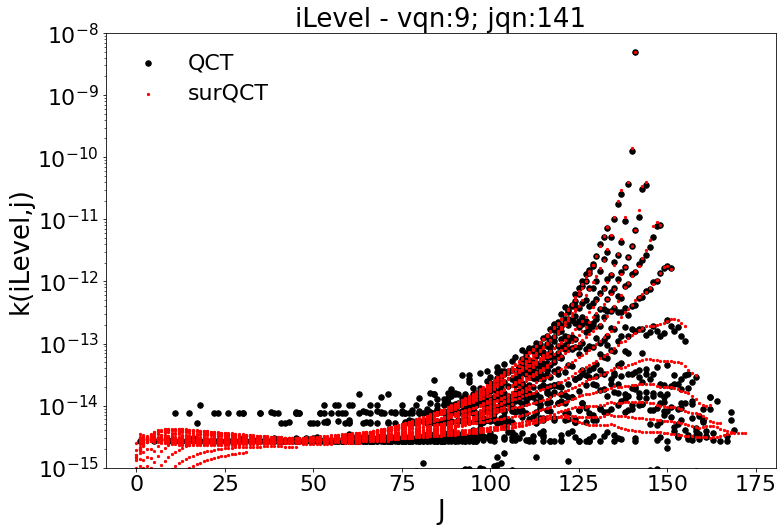

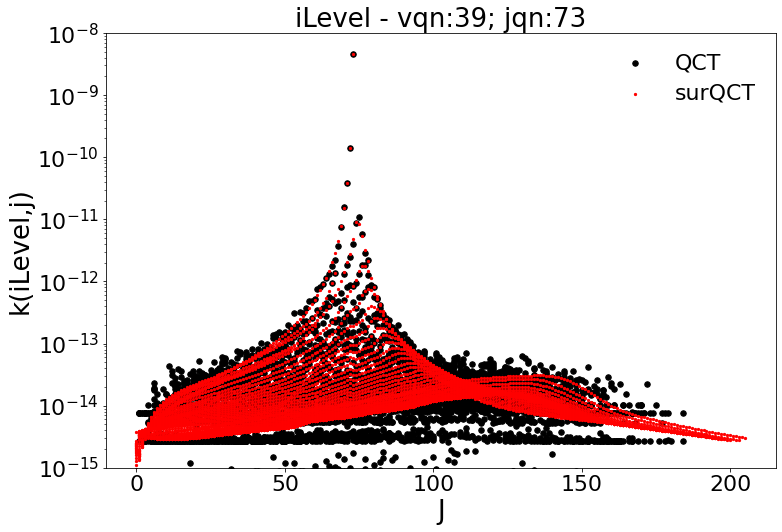

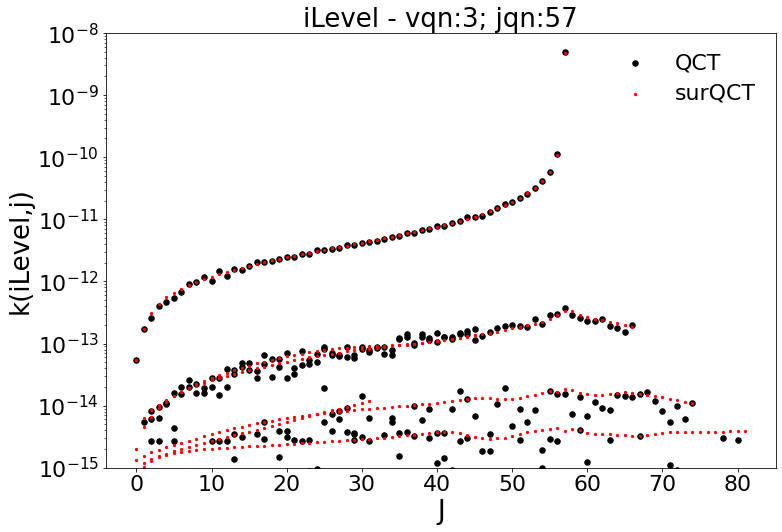

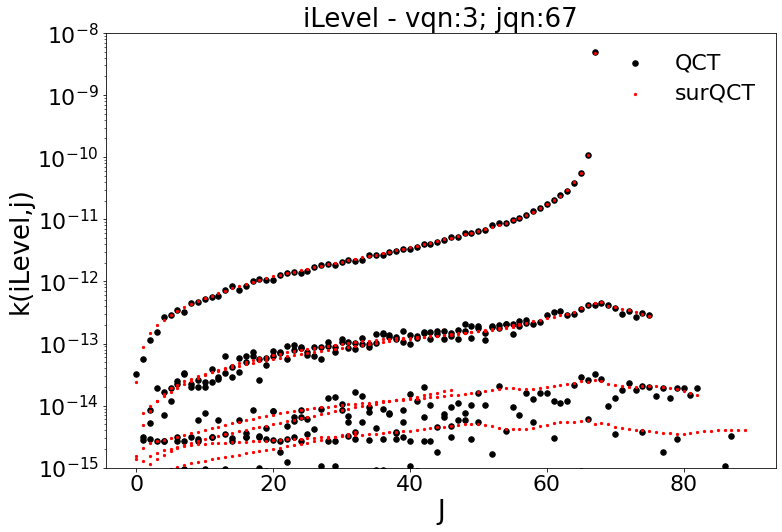

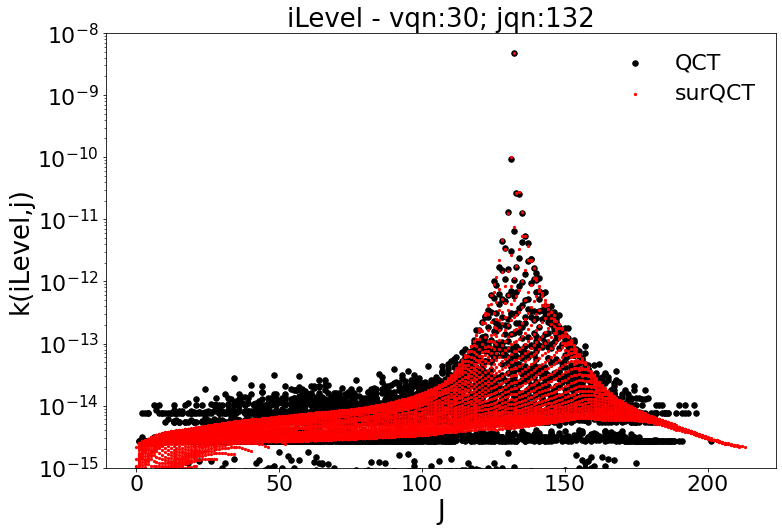

...

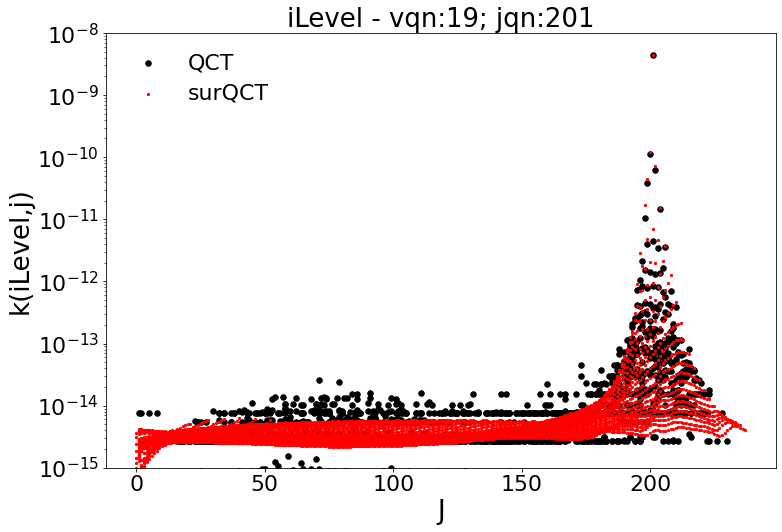

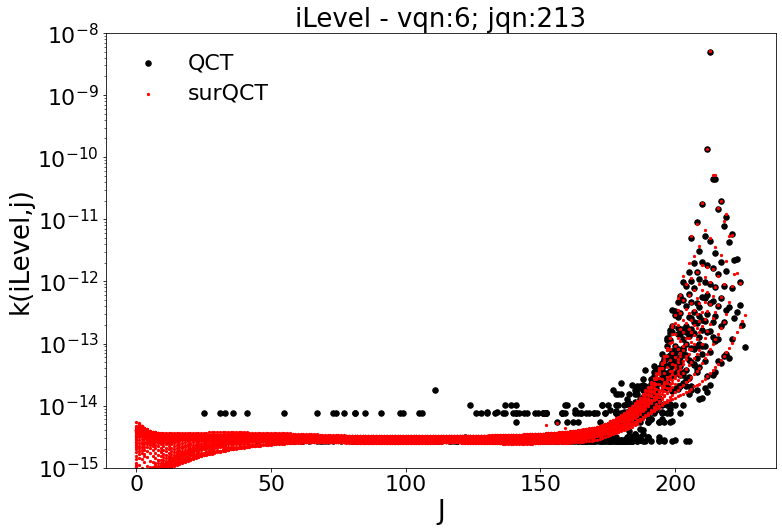

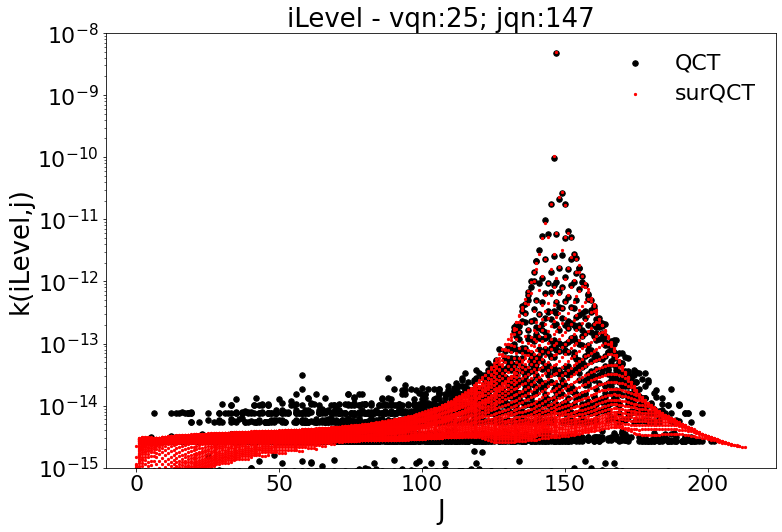

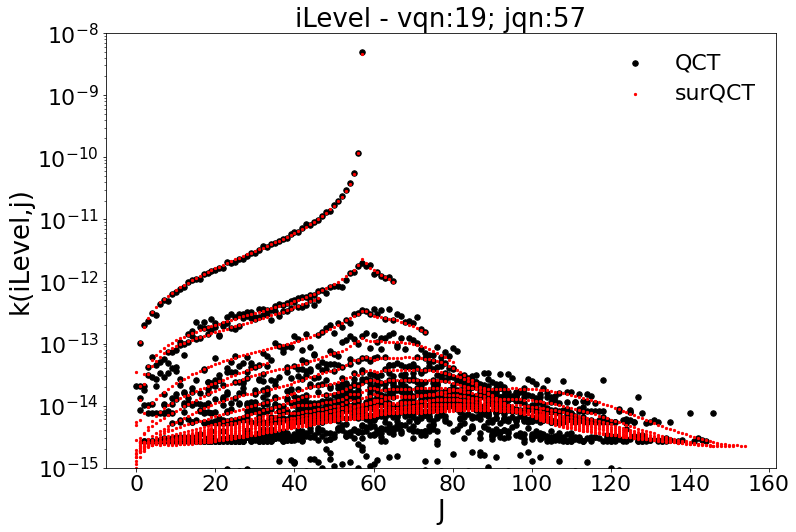

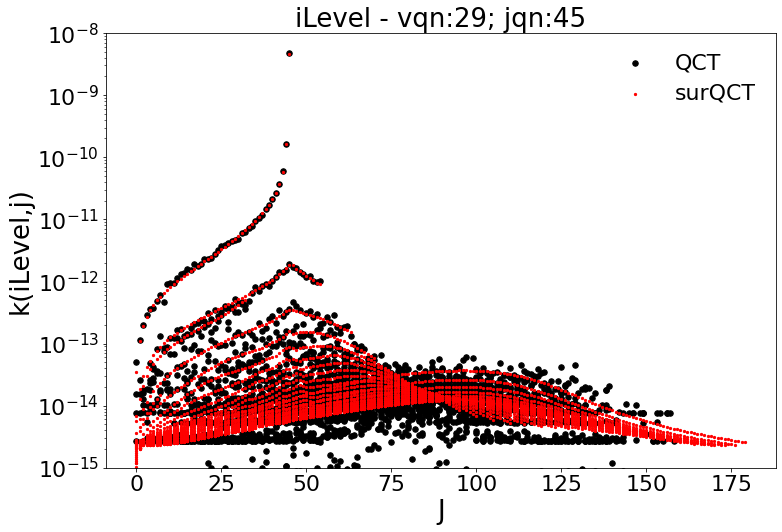

In [20]:
Str = 'q_'+str(int(TTran))
for iIdx in tqdm(rnd.choices(list(iIdxVec), k=NIdx), desc='[SurQCT]:     Generating Inelastic and Exchange Rate Matrixes'):
    print('Level: '+str(iIdx)+'; vqn: '+str(DiatData[0]['vqn'].to_numpy()[iIdx])+'; jqn:'+str(DiatData[0]['jqn'].to_numpy()[iIdx]))
    time.sleep(0.02)
    
    if (InputData.ExoEndoFlg):
        jIdxVec           = [jIdx for jIdx in np.arange(NLevels[1]) if (DiatData[1]['EInt'].to_numpy()[jIdx] <= DiatData[0]['EInt'].to_numpy()[iIdx])]
        jIdxVecNo         = [jIdx for jIdx in np.arange(NLevels[1]) if (DiatData[1]['EInt'].to_numpy()[jIdx] > DiatData[0]['EInt'].to_numpy()[iIdx])]
        RatioNo           = [DiatData[0][Str].to_numpy()[iIdx]/DiatData[1][Str].to_numpy()[jIdx] for jIdx in np.arange(NLevels[1]) if (DiatData[1]['EInt'].to_numpy()[jIdx] > DiatData[0]['EInt'].to_numpy()[iIdx])]
    else:
        jIdxVec           = [jIdx for jIdx in np.arange(NLevels[1]) if (DiatData[1][Str].to_numpy()[jIdx]    >= DiatData[0][Str].to_numpy()[iIdx])]
        jIdxVecNo         = [jIdx for jIdx in np.arange(NLevels[1]) if (DiatData[1][Str].to_numpy()[jIdx]    < DiatData[0][Str].to_numpy()[iIdx])]
        RatioNo           = [DiatData[0][Str].to_numpy()[iIdx]/DiatData[1][Str].to_numpy()[jIdx] for jIdx in np.arange(NLevels[1]) if (DiatData[1][Str].to_numpy()[jIdx]    < DiatData[0][Str].to_numpy()[iIdx])]
    jNLevels              = len(jIdxVec)
    jNLevelsNo            = len(jIdxVecNo)
    
    
    ### FWD Rates
    iiIdxVec              = [iIdx]*jNLevels
    
    TTranVec              = np.ones((jNLevels))*TTran
    TTranDataTemp         = pd.DataFrame({'TTran': TTranVec})
    TTranDataTemp.index   = jIdxVec

    
    iLevelsDataTemp       = LevelsData[0].iloc[iiIdxVec,:].copy()
    iLevelsDataTemp.index = jIdxVec

    jLevelsDataTemp       = LevelsData[1].iloc[jIdxVec,:].copy()        
    if (OtherVar == '_Delta'):
        jLevelsDataTemp   = iLevelsDataTemp.subtract(jLevelsDataTemp) 
    else:
        jLevelsDataTemp   = jLevelsDataTemp
    jLevelsDataTemp.index = jIdxVec
    
    kLevelsDataTemp       = LevelsData[1].iloc[jIdxVec,:].copy()        
    kLevelsDataTemp.index = jIdxVec

    
    iLevelsData           = pd.concat([iLevelsDataTemp[xVarsVec_i], TTranDataTemp], axis=1)
    iLevelsData.columns   = [(VarName + '_i') for VarName in iLevelsData.columns]
    
    jLevelsData           = pd.concat([jLevelsDataTemp[xVarsVec_Delta], TTranDataTemp], axis=1)
    jLevelsData.columns   = [(VarName + OtherVar) for VarName in jLevelsData.columns]

    kLevelsData           = pd.concat([kLevelsDataTemp[xVarsVec_i], TTranDataTemp], axis=1)
    kLevelsData.columns   = [(VarName + '_j') for VarName in kLevelsData.columns]
    
    xTemp_FWD             = pd.concat([iLevelsData, jLevelsData, kLevelsData], axis=1)
    
    if (len(xTemp_FWD[NN_KExcit.xTrainingVar]) > 0):
        KExcit_NN_FWD          = np.exp( NN_KExcit.Model.predict(xTemp_FWD[NN_KExcit.xTrainingVar]) ) / InputData.MultFact
    
    
    
#     ## BWD Rates
#     iiIdxVec              = jIdxVecNo
#     jIdxVec               = [iIdx]*jNLevelsNo
    
#     TTranVec              = np.ones((jNLevelsNo))*TTran
#     TTranDataTemp         = pd.DataFrame({'TTran': TTranVec})
#     TTranDataTemp.index   = iiIdxVec

    
#     iLevelsDataTemp       = LevelsData[0].iloc[iiIdxVec,:].copy()
#     iLevelsDataTemp.index = iiIdxVec

#     jLevelsDataTemp       = LevelsData[1].iloc[jIdxVec,:].copy() 
#     jLevelsDataTemp.index = iiIdxVec
#     if (OtherVar == '_Delta'):
#         jLevelsDataTemp   = iLevelsDataTemp.subtract(jLevelsDataTemp) 
#     else:
#         jLevelsDataTemp   = jLevelsDataTemp
    
#     kLevelsDataTemp       = LevelsData[1].iloc[jIdxVec,:].copy()        
#     kLevelsDataTemp.index = iiIdxVec

    
#     iLevelsData           = pd.concat([iLevelsDataTemp[xVarsVec_i], TTranDataTemp], axis=1)
#     iLevelsData.columns   = [(VarName + '_i') for VarName in iLevelsData.columns]
    
#     jLevelsData           = pd.concat([jLevelsDataTemp[xVarsVec_Delta], TTranDataTemp], axis=1)
#     jLevelsData.columns   = [(VarName + OtherVar) for VarName in jLevelsData.columns]

#     kLevelsData           = pd.concat([kLevelsDataTemp[xVarsVec_i], TTranDataTemp], axis=1)
#     kLevelsData.columns   = [(VarName + '_j') for VarName in kLevelsData.columns]
    
#     xTempp_BWD            = pd.concat([iLevelsData, jLevelsData, kLevelsData], axis=1)
    
#     if (len(xTempp_BWD[NN_KExcit.xTrainingVar]) > 0):
#         KExcit_NN_BWD          = np.exp( NN_KExcit.Model.predict(xTempp_BWD[NN_KExcit.xTrainingVar]) ) / InputData.MultFact
#         KExcit_NN_BWD[:,0]     = KExcit_NN_BWD[:,0] / RatioNo


#         iLevelsData           = pd.concat([iLevelsDataTemp[xVarsVec_i], TTranDataTemp], axis=1)
#         iLevelsData.columns   = [(VarName + '_j') for VarName in iLevelsData.columns]

#         jLevelsData           = pd.concat([jLevelsDataTemp[xVarsVec_Delta], TTranDataTemp], axis=1)
#         jLevelsData.columns   = [(VarName + OtherVar) for VarName in jLevelsData.columns]

#         kLevelsData           = pd.concat([kLevelsDataTemp[xVarsVec_i], TTranDataTemp], axis=1)
#         kLevelsData.columns   = [(VarName + '_i') for VarName in kLevelsData.columns]

#         xTemp_BWD             = pd.concat([iLevelsData, jLevelsData, kLevelsData], axis=1)


        
#     ### Concatenating
#         if (len(xTemp_FWD[NN_KExcit.xTrainingVar]) > 0):
#             xTemp     = pd.concat([xTemp_FWD, xTemp_BWD], axis=0)
#             KExcit_NN = np.concatenate((KExcit_NN_FWD, KExcit_NN_BWD), axis=0)
#         else:
#             xTemp     = xTemp_BWD
#             KExcit_NN = KExcit_NN_BWD
#     else:
#         if (len(xTemp_FWD[NN_KExcit.xTrainingVar]) > 0):
#             xTemp     = xTemp_FWD
#             KExcit_NN = KExcit_NN_FWD
    
    xTemp     = xTemp_FWD
    KExcit_NN = KExcit_NN_FWD
    
    ### Plotting
    Mask     = KExcit[iIdx,:] > MinRate
        
    j_color = xTemp['jqn_j'] % 2
    cmap=mpl.colors.ListedColormap(["navy","crimson","limegreen","gold","k","r","b","y","c"])
    cmap1=mpl.colors.ListedColormap(["gold","r"])
    fig = plt.figure(figsize=(12,8))

    label_plot = "iLevel - vqn:" + str(DiatData[0]['vqn'].to_numpy()[iIdx])+"; jqn:"+str(DiatData[0]['jqn'].to_numpy()[iIdx])
    plt.scatter(DiatData[1]['jqn'], KExcit[iIdx,:], c='k', s=30,label='QCT')
    plt.scatter(xTemp['jqn_j'], KExcit_NN[:,0], s=5, c='r', label='surQCT')
    plt.yscale('log')
    plt.legend(['QCT','surQCT'],frameon=False)
    plt.ylim([1.e-15, 1.e-8])
    plt.xlabel('J')
    plt.ylabel('k(iLevel,j)')
    plt.title(label_plot)
        

In [19]:
np.power((2.397**2+2.832**2-2*2.832*2.397*np.cos(117.8/180*np.pi)),0.5)

4.4830549396958865

In [20]:
2.397**2+2.832**2-2*2.832*2.397*np.cos(117.8/180*np.pi)

20.097781592331685

In [21]:
np.arccos((20.097781592331685 + 2.397**2 - 2.832**2)/(2*2.397*4.4830549396958865))*180/np.pi

33.97288454435111